# Application 10 · A robot arm and a chaotic map

**Builds on:** [Lecture 10](../notebooks/10_nonlinear_systems.ipynb) (Krawczyk test) and Lecture 08 (`jacobian2`).

**Time:** about 75 minutes. **You will certify:**

- **Part A:** that a two-link robot arm reaches every point of a planned path, with exactly one elbow-up configuration near the computed one, and where this breaks down;
- **Part B:** periodic orbits of the Hénon map, a standard example of chaos.

Both parts use the Krawczyk test on 2 × 2 systems. The new ingredient in Part A is a **parametric** certificate: one Krawczyk computation covers infinitely many targets at once.

## Google Colab setup — run this cell first

**Local Jupyter:** this cell skips Colab setup; use your installed course environment.

Use a **CPU Python runtime** (Python 3.12 or newer). Run the next cell and select
**vc_runtime.zip** from this edition when prompted. It loads the course helpers
and installs the arithmetic libraries. Repeat setup whenever you get a new runtime.
No Drive mounting or local Python installation is required.
Use this setup instead of the local installation and kernel-selection instructions
in the original course text.

Save a copy of this notebook in Drive, or download it after editing. Files created
by the project are under `/content/validated-course/build/certificates/`; download
those separately from Colab's Files panel. Runtime files are temporary.

Open other course notebooks using **File → Upload notebook**, choosing them from
the extracted course folder. Relative course links are intended for local Jupyter
and do not open sibling notebooks automatically in Colab.


In [1]:
try:
    import google.colab
except ImportError:
    print("Local Jupyter: using the installed course environment.")
else:
    import hashlib
    from pathlib import Path
    import subprocess
    import sys
    from google.colab import files

    if sys.version_info < (3, 12):
        raise RuntimeError("This course needs a Python 3.12 or newer Colab runtime.")

    # Upload the small companion file supplied with the Colab course edition.
    expected_hash = '833652c4a440f1c3a22bc6e68c59d533b41e6f9f1ff0b4af226f8fbee2244c1a'
    runtime_zip = Path("/content") / ("vc-course-" + expected_hash + ".zip")
    if not runtime_zip.exists():
        print("Select vc_runtime.zip from the extracted Colab course folder.")
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Upload only vc_runtime.zip, then run this cell again.")
        archive_bytes = next(iter(uploaded.values()))
        if hashlib.sha256(archive_bytes).hexdigest() != expected_hash:
            raise ValueError("Wrong vc_runtime.zip: use the one supplied with this notebook.")
        runtime_zip.write_bytes(archive_bytes)

    if hashlib.sha256(runtime_zip.read_bytes()).hexdigest() != expected_hash:
        raise ValueError("The cached vc archive has changed; start a fresh runtime.")

    # Keep Colab's existing NumPy and plotting stack when they satisfy these bounds.
    # Install MPFR/Arb bindings, not the full local Jupyter environment.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        'numpy>=1.26', 'matplotlib>=3.8', 'gmpy2==2.3.1', 'python-flint==0.9.0', 'jupytext>=1.16'
    ])
    import gmpy2
    import flint
    if gmpy2.version() != "2.3.1" or flint.__version__ != "0.9.0":
        raise RuntimeError("Old arithmetic libraries are still loaded. Restart the session and run setup first.")

    if str(runtime_zip) not in sys.path:
        sys.path.insert(0, str(runtime_zip))

    import vc
    if not vc.__file__.startswith(str(runtime_zip) + "/"):
        raise RuntimeError("Another vc copy is already loaded. Start a fresh runtime.")

    # Preserve the relative output paths used by the project notebooks.
    import os
    working_folder = Path("/content/validated-course") / 'applications'
    working_folder.mkdir(parents=True, exist_ok=True)
    os.chdir(working_folder)
    print("Course helpers ready:", vc.__version__)

Local Jupyter: using the installed course environment.


In [2]:
from fractions import Fraction
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from vc.intervals import RationalInterval as Interval
from vc.autodiff import jacobian2
from vc.systems import krawczyk, midpoint_inverse

# Part A · Inverse kinematics of a two-link arm

The shoulder is at the origin. The first link has length L₁ = 1 and ends at the elbow (u, v). The second link has length L₂ = 3/4 and ends at the hand, which must reach the target (x, y). Writing the unknowns as the **elbow position** gives polynomial equations:

$$u^2+v^2-L_1^2=0,\qquad (u-x)^2+(v-y)^2-L_2^2=0.$$

The elbow lies on two circles: one around the shoulder, one around the target. Usually there are two solutions (elbow up and elbow down). The joint angles follow from the elbow position with atan2.

The reachable targets form the annulus L₁ − L₂ ≤ |(x, y)| ≤ L₁ + L₂. On its boundary the two circles touch, the arm is fully stretched or folded, and the Jacobian is singular.

In [3]:
L1, L2 = Fraction(1), Fraction(3, 4)

def arm_equations(target):
    x, y = target           # numbers or intervals
    def system(u, v):
        return [u*u + v*v - L1*L1, (u - x)*(u - x) + (v - y)*(v - y) - L2*L2]
    return system

def elbow_up_float(x, y):
    """Closed-form circle intersection in binary64: an approximation only."""
    x, y = float(x), float(y)
    d = math.hypot(x, y)
    a = (float(L1)**2 - float(L2)**2 + d*d) / (2*d)      # distance along the shoulder-target line
    h = math.sqrt(max(float(L1)**2 - a*a, 0.0))          # offset perpendicular to it
    return a*x/d - h*y/d, a*y/d + h*x/d

## A certificate for a whole set of targets

Let the target be an **interval box** T instead of a point. Evaluate the residual and the Jacobian with interval targets. If the Krawczyk image lands strictly inside the elbow box X and the contraction bound is below 1, the theorem applies to each fixed target t ∈ T separately (each one is a point inside the intervals used). So:

> for every target in T, there is exactly one elbow position in X.

This is much stronger than checking sample targets. A path made of finitely many target boxes is certified for all of its infinitely many points.

In [4]:
def to_rational(value):
    return Fraction(value).limit_denominator(10**8)

def certify_targets(target_box, radii=(Fraction(1, 4), Fraction(1, 8), Fraction(1, 16), Fraction(1, 32))):
    """Try elbow boxes of decreasing size around the float solution at the box center."""
    system = arm_equations(target_box)
    jacobian = lambda box: jacobian2(system, box)
    guess = elbow_up_float(target_box[0].midpoint(), target_box[1].midpoint())
    center = [to_rational(guess[0]), to_rational(guess[1])]
    for radius in radii:
        elbow_box = [Interval(c - radius, c + radius) for c in center]
        certificate = krawczyk(system, jacobian, elbow_box, midpoint_inverse(jacobian(elbow_box)))
        if certificate.status == "unique_root":
            return certificate
    return None

single = certify_targets([Interval(1), Interval(Fraction(1, 2))])
u, v = single.image
print("single target:", single.status)
print(f"elbow in [{float(u.lo):.6f}, {float(u.hi):.6f}] x [{float(v.lo):.6f}, {float(v.hi):.6f}]")

single target: unique_root
elbow in [0.151762, 0.611404] x [0.753929, 1.094740]


## Certify a planned path

The hand moves along the straight segment from P₀ = (−1/2, 6/5) to P₁ = (7/4, 0). The end point lies exactly on the outer limit |t| = L₁ + L₂: there the arm is fully stretched and the two solutions merge.

For a piece s ∈ [s₀, s₁] of the path, the box spanned by its two end points contains the whole piece. If that box cannot be certified, we split the piece. Pieces shorter than 1/1024 of the path are reported as **not certified**: we do not pretend.

In [5]:
P0 = (Fraction(-1, 2), Fraction(6, 5))
P1 = (Fraction(7, 4), Fraction(0))

def path_point(s):
    return (P0[0] + s*(P1[0] - P0[0]), P0[1] + s*(P1[1] - P0[1]))

def piece_box(s0, s1):
    a, b = path_point(s0), path_point(s1)
    return [Interval(min(a[0], b[0]), max(a[0], b[0])), Interval(min(a[1], b[1]), max(a[1], b[1]))]

def certify_path(s0, s1, shortest=Fraction(1, 1024)):
    certificate = certify_targets(piece_box(s0, s1))
    if certificate is not None:
        return [(s0, s1, certificate)]
    if s1 - s0 <= shortest:
        return [(s0, s1, None)]
    middle = (s0 + s1) / 2
    return certify_path(s0, middle, shortest) + certify_path(middle, s1, shortest)

pieces = certify_path(Fraction(0), Fraction(1))
certified = [p for p in pieces if p[2] is not None]
print(f"{len(pieces)} pieces, {len(certified)} certified, "
      f"covering {float(sum(p[1] - p[0] for p in certified)):.4f} of the path")
print("shortest certified piece:", min(p[1] - p[0] for p in certified))

47 pieces, 44 certified, covering 0.9971 of the path
shortest certified piece: 1/1024


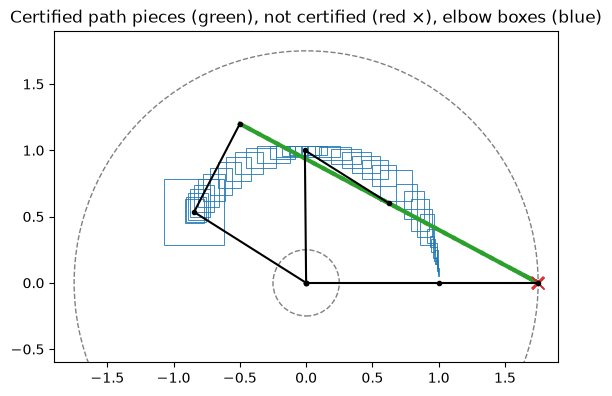

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.add_patch(Circle((0, 0), float(L1 + L2), fill=False, linestyle="--", color="gray"))
ax.add_patch(Circle((0, 0), float(L1 - L2), fill=False, linestyle="--", color="gray"))
for s0, s1, certificate in pieces:
    a, b = path_point(s0), path_point(s1)
    color = "tab:green" if certificate else "tab:red"
    ax.plot([float(a[0]), float(b[0])], [float(a[1]), float(b[1])], color=color, linewidth=3)
    if certificate:
        u, v = certificate.image
        ax.add_patch(Rectangle((float(u.lo), float(v.lo)), float(u.width()), float(v.width()),
                               fill=False, color="tab:blue", linewidth=0.6))
    else:                                                   # too short to see: mark it
        ax.plot(float(a[0]), float(a[1]), "x", color="tab:red", markersize=9)
for s in [Fraction(0), Fraction(1, 2), Fraction(1)]:      # draw the arm at three targets
    target = path_point(s)
    elbow = elbow_up_float(*target)
    ax.plot([0, elbow[0], float(target[0])], [0, elbow[1], float(target[1])], "k-o", markersize=3)
ax.set(aspect="equal", xlim=(-1.9, 1.9), ylim=(-0.6, 1.9),
       title="Certified path pieces (green), not certified (red ×), elbow boxes (blue)")
plt.close(fig)
display(fig)

**Reading the result.** Near the start the pieces are long. As the path approaches the outer circle, the pieces must shrink: near a singular configuration a small change of the target moves the elbow a lot, so the elbow box must be large while the Krawczyk contraction gets weaker. The last pieces, which touch the boundary, cannot be certified at all. That is the correct outcome: at the stretched configuration the two solutions merge into a double solution and the Jacobian is singular. Every elbow box around it contains two solutions for nearby targets, and the Krawczyk test (which needs a nonsingular Jacobian) cannot succeed.

**Engineering reading.** "The planner's float IK never failed on 1000 sample points" says nothing about the points in between. The certificate covers the whole segment, and it also shows *where* the arm works close to a singularity, which is where small control errors turn into large joint motions.

# Part B · Periodic orbits of the Hénon map

$$H(x,y)=(1-a x^2+y,\; b x),\qquad a=\tfrac{7}{5},\; b=\tfrac{3}{10}.$$

Iterating H from almost any start produces the famous strange attractor. Orbits are chaotic: nearby starts separate exponentially, so a float simulation cannot follow a single orbit for long. Yet we can **prove** that certain orbits exist exactly. A point p has period dividing k if H^k(p) = p, a 2 × 2 system:

$$G_k(p)=H^k(p)-p=0.$$

In [7]:
a, b = Fraction(7, 5), Fraction(3, 10)

def henon(x, y):
    return 1 - a*x*x + y, b*x

def periodic_system(k):
    def G(x, y):
        px, py = x, y
        for _ in range(k):
            px, py = henon(px, py)
        return [px - x, py - y]
    return G

**Finding candidates.** Newton's method from random starts finds approximate solutions. The Jacobian comes from the same `jacobian2`, now with float components (Lecture 08: the component arithmetic decides the guarantee, and floats give none).

In [8]:
def newton_float(G, point, steps=40):
    x, y = point
    for _ in range(steps):
        (j11, j12), (j21, j22) = jacobian2(G, (x, y))
        f1, f2 = G(x, y)
        det = j11*j22 - j12*j21
        if det == 0 or not math.isfinite(det):
            return None
        x, y = x - (j22*f1 - j12*f2)/det, y - (j11*f2 - j21*f1)/det
        if abs(x) > 10 or abs(y) > 10:
            return None
    return (x, y)

def find_candidates(k, starts=300, seed=1):
    rng = np.random.default_rng(seed)
    G = periodic_system(k)
    found = []
    for _ in range(starts):
        point = newton_float(G, tuple(rng.uniform(-1.5, 1.5, 2)))
        if point is None:
            continue
        residual = max(abs(c) for c in G(*point))
        is_new = all(max(abs(point[0] - q[0]), abs(point[1] - q[1])) > 1e-6 for q in found)
        if residual < 1e-9 and is_new:
            found.append(point)
    return found

**Certifying.** Around each candidate, try Krawczyk on boxes of radius 10⁻⁸, 10⁻⁶ and 10⁻⁴, with exact rational arithmetic. A success proves a unique exact periodic point in the box. A candidate that no box certifies stays a candidate.

In [9]:
def certify_periodic(G, point):
    jacobian = lambda box: jacobian2(G, box)
    center = [to_rational(point[0]), to_rational(point[1])]
    for radius in [Fraction(1, 10**8), Fraction(1, 10**6), Fraction(1, 10**4)]:
        box = [Interval(c - radius, c + radius) for c in center]
        certificate = krawczyk(G, jacobian, box, midpoint_inverse(jacobian(box)))
        if certificate.status == "unique_root":
            return certificate
    return None

certified_points = {}
for k in [1, 2, 4, 6]:
    G = periodic_system(k)
    candidates = find_candidates(k)
    certificates = [certify_periodic(G, p) for p in candidates]
    certified_points[k] = [c for c in certificates if c is not None]
    print(f"period dividing {k}: {len(candidates):2d} float candidates, {len(certified_points[k]):2d} certified")

period dividing 1:  2 float candidates,  2 certified


period dividing 2:  4 float candidates,  4 certified


period dividing 4:  8 float candidates,  8 certified


period dividing 6: 16 float candidates, 16 certified


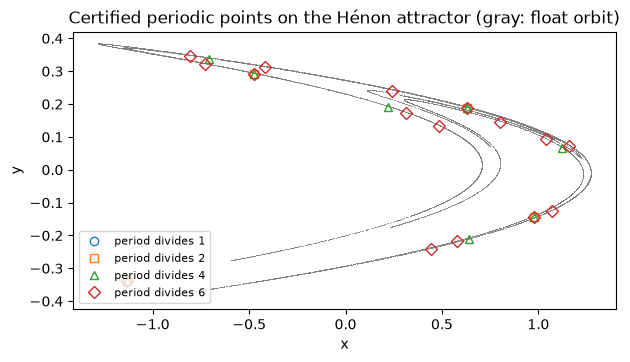

In [10]:
orbit = [(0.1, 0.1)]
for _ in range(20000):
    orbit.append(henon(*orbit[-1]))                       # float iteration, for the picture only
orbit = np.array([(float(x), float(y)) for x, y in orbit[100:]])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(orbit[:, 0], orbit[:, 1], ",", color="gray", alpha=0.6)
for k, marker in zip([1, 2, 4, 6], ["o", "s", "^", "D"]):
    xs = [float(c.box[0].midpoint()) for c in certified_points[k]]
    ys = [float(c.box[1].midpoint()) for c in certified_points[k]]
    ax.plot(xs, ys, marker, fillstyle="none", label=f"period divides {k}")
ax.set(xlabel="x", ylabel="y", title="Certified periodic points on the Hénon attractor (gray: float orbit)")
ax.legend(fontsize=8, loc="lower left")
plt.close(fig)
display(fig)

**What is proved and what is not.** Each certified box contains exactly one exact point with H^k(p) = p. We did **not** prove that we found *all* such points: random Newton starts give no completeness. A complete count needs a search that excludes the rest of the plane region, as in Lecture 09. Research papers do exactly this and obtain rigorous counts of periodic orbits up to high periods.

Note also the contrast with the gray picture. The float orbit is a numerical experiment that cannot be trusted point by point, while every marker is a theorem.

## Exercises

1. **Inner boundary.** Plan a path that passes close to the inner circle |t| = 1/4. Where does certification fail, and what is the arm doing there?
2. **Joint angles.** Use Arb (`arb.atan2`) to turn one certified elbow box into enclosures of the two joint angles θ₁ and θ₂. Which angle is more sensitive near the outer boundary?
3. **Elbow down.** Modify `elbow_up_float` to return the other solution and certify the same path. Why do the two certificates never overlap?
4. **Minimal period.** A point with H²(p) = p might be a fixed point. Use the certified boxes to prove that some of your period-2 points have minimal period exactly 2. (Hint: compare with the fixed-point boxes, or show H(X) ∩ X = ∅.)